In [1]:
import numpy as np
import matplotlib.pyplot as plt
from matplotlib.lines import Line2D
import dill

In [2]:
# Definizione lunghezza link
l0 = 0.11
l1 = 0.065
l2 = 0.065
l3 = 0.03
d_3 = 0.03
d_4 = 0.105

# Calcolo singola trasformazione omogenea (DENAVIT-HARTENBERG)
def DH_computation(alpha, a, d, theta):
    T = np.array([[np.cos(theta), -np.sin(theta)*np.cos(alpha), np.sin(theta)*np.sin(alpha), a*np.cos(theta)],
                [np.sin(theta), np.cos(theta)*np.cos(alpha), -np.cos(theta)*np.sin(alpha), a*np.sin(theta)],
                [0, np.sin(alpha), np.cos(alpha), d],
                [0, 0, 0, 1]])
    return T

# Definizione dei parametri di Denavit-Hartenberg
a1 = l1
a2 = l2
a3 = 0
a4 = l3
alpha1 = -np.pi/2
alpha2 = np.pi/2
alpha3 = -np.pi/2
alpha4 = 0
d1 = 0
d2 = 0
d3 = -d_3
d4 = d_4

In [3]:
# Configurazione iniziale manipolatore
q0 = np.array([0,0,0,0])

# Calcolo matrice di trasformazione tra base e end-effector
Tb0 = DH_computation(np.pi/2,0,0,0)
T01 = DH_computation(alpha1,a1,d1,q0[0])
T12 = DH_computation(alpha2,a2,d2,q0[1])
T23 = DH_computation(alpha3,a3,d3,q0[2])
T34 = DH_computation(alpha4,a4,d4,q0[3])
Tb1 = np.matmul(Tb0,T01)
Tb2 = np.matmul(Tb1,T12)
Tb3 = np.matmul(Tb2,T23)
Tb4 = np.matmul(Tb3,T34)

# Estraggo gli assi e le posizioni delle varie terne
x0_i = Tb0[:3,0]
y0_i = Tb0[:3,1]
z0_i = Tb0[:3,2]
p0 = Tb0[:3,3]

x1_i = Tb1[:3,0]
y1_i = Tb1[:3,1]
z1_i = Tb1[:3,2]
p1 = Tb1[:3,3]

x2_i = Tb2[:3,0]
y2_i = Tb2[:3,1]
z2_i = Tb2[:3,2]
p2 = Tb2[:3,3]

x3_i = Tb3[:3,0]
y3_i = Tb3[:3,1]
z3_i = Tb3[:3,2]
p3 = Tb3[:3,3]

pee = Tb4[:3,3]

print('Tb4',Tb4)
print('pee',pee)


Tb4 [[1.    0.    0.    0.16 ]
 [0.    1.    0.    0.03 ]
 [0.    0.    1.    0.105]
 [0.    0.    0.    1.   ]]
pee [0.16  0.03  0.105]


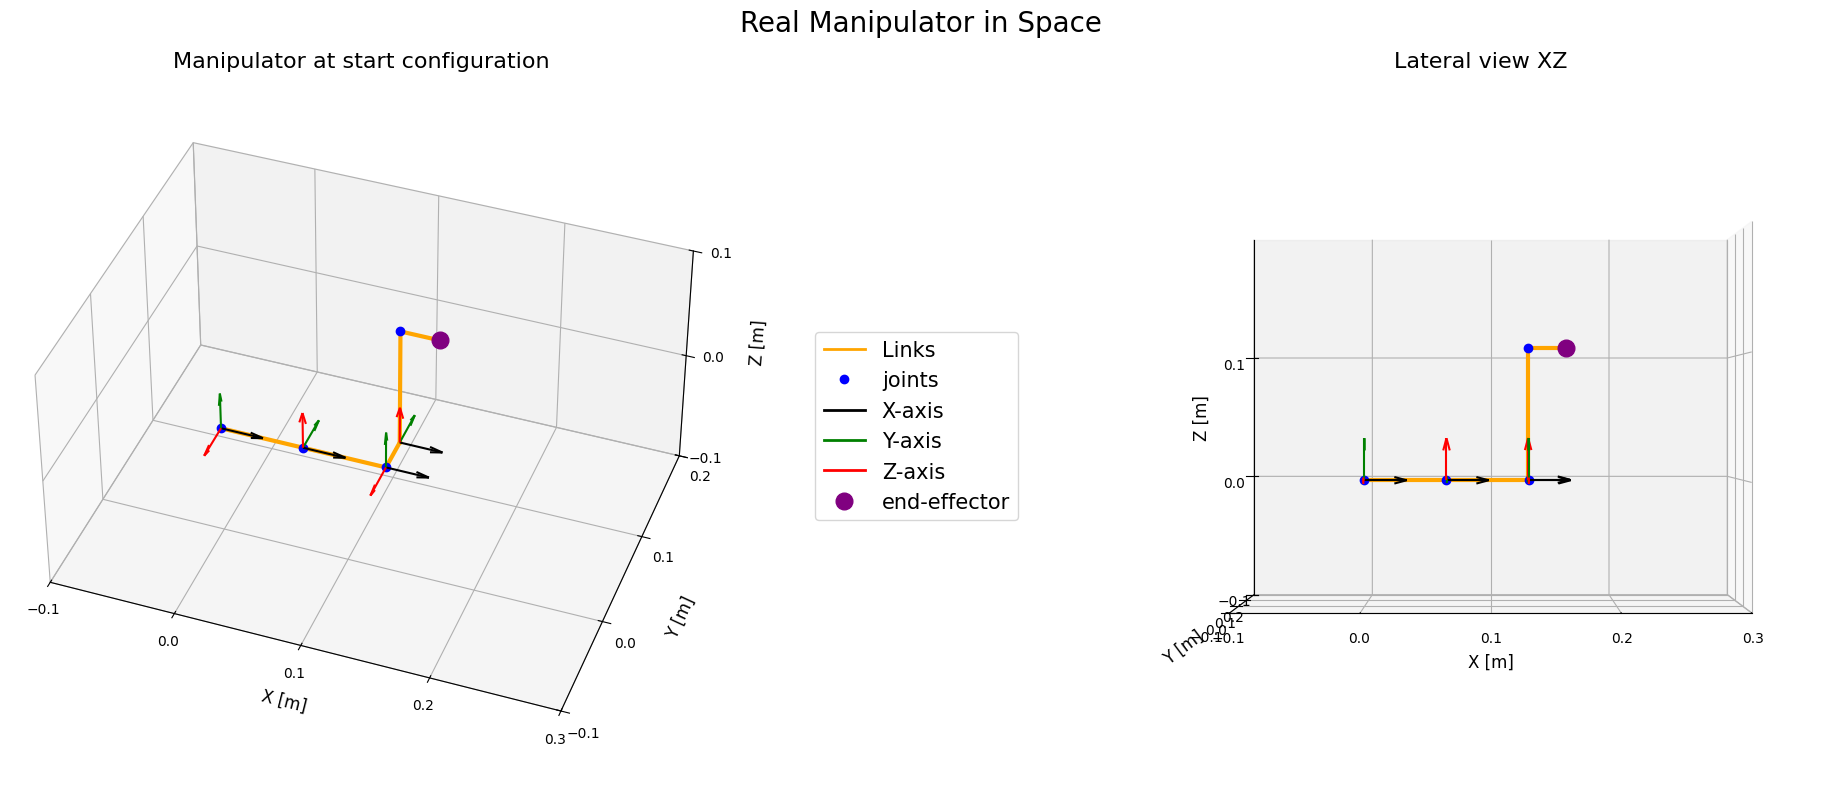

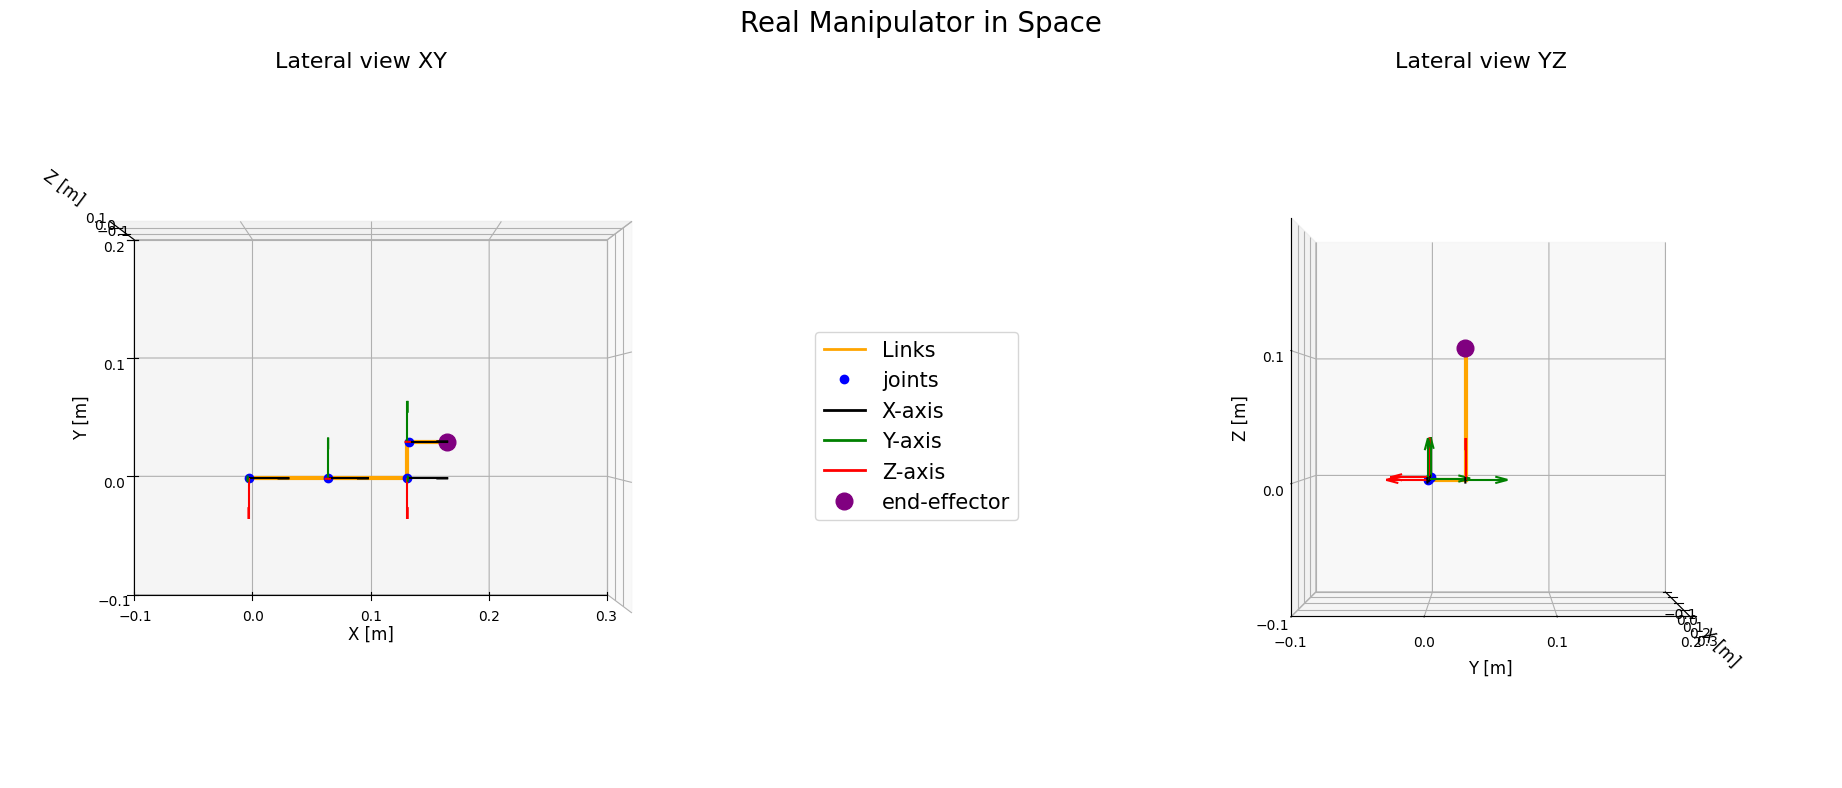

In [4]:
# Plot della configurazione iniziale 
fig = plt.figure(figsize=(22,8))
ax = fig.add_subplot(121, projection='3d')
ax.set_title('Manipulator at start configuration', fontsize=16)

# Disegno i link
ax.plot3D([p0[0],p1[0]], [p0[1],p1[1]], [p0[2],p1[2]], lw=3, color='orange')
ax.plot3D([p1[0],p2[0]], [p1[1],p2[1]], [p1[2],p2[2]], lw=3, color='orange')
ax.plot3D([p2[0],p3[0]], [p2[1],p3[1]], [p2[2],p3[2]], lw=3, color='orange')
ax.plot3D([p3[0],p3[0]], [p3[1],p3[1]], [p3[2],p3[2]+d4], lw=3, color='orange')
ax.plot3D([p3[0],pee[0]], [p3[1],pee[1]], [p3[2]+d4,pee[2]], lw=3, color='orange')

# Disegno i giunti e gli assi
for p, x_i, y_i, z_i in zip([p0, p1, p2, p3], [x0_i, x1_i, x2_i, x3_i], [y0_i, y1_i, y2_i, y3_i], [z0_i, z1_i, z2_i, z3_i]):
    ax.quiver(p[0], p[1], p[2], x_i[0]/30, x_i[1]/30, x_i[2]/30, color='k', label='X-axis')
    ax.quiver(p[0], p[1], p[2], y_i[0]/30, y_i[1]/30, y_i[2]/30, color='g', label='Y-axis')
    ax.quiver(p[0], p[1], p[2], z_i[0]/30, z_i[1]/30, z_i[2]/30, color='r', label='Z-axis')

ax.plot3D(p0[0], p0[1], p0[2], '.', ms=12, c='blue')
ax.plot3D(p1[0], p1[1], p1[2], '.', ms=12, c='blue')
ax.plot3D(p2[0], p2[1], p2[2], '.', ms=12, c='blue')
ax.plot3D(p3[0], p3[1], p3[2]+d4, '.', ms=12, c='blue')
ax.plot3D(pee[0], pee[1], pee[2], 'o', ms=12, color='purple', label='End Effector')

# Definizione degli elementi della legenda per i versori
legend_elements = [
    Line2D([0], [0], color='orange', lw=2, label='Links'),
    Line2D([0], [0], marker = '.', ms=12, linestyle='None', color='blue', label='joints'),
    Line2D([0], [0], color='k', lw=2, label='X-axis'),
    Line2D([0], [0], color='g', lw=2, label='Y-axis'),
    Line2D([0], [0], color='r', lw=2, label='Z-axis'),
    Line2D([0], [0], marker = 'o', ms=12, linestyle='None', color='purple', label='end-effector')
]
# Legenda e aspetto grafico
ax.legend(handles=legend_elements, loc='best', fontsize=15, bbox_to_anchor=(1, 0.15, 0.45, 0.5))

ax.set_xlim([-0.1, 0.2])
ax.set_ylim([-0.1, 0.2])
ax.set_zlim([-0.1, 0.1])

ax.set_xticks(np.arange(-0.1,0.35,0.1))
ax.set_yticks(np.arange(-0.1, 0.25, 0.1))
ax.set_zticks(np.arange(-0.1,0.15,0.1))

ax.set_xlabel('X [m]', fontsize=12, labelpad=10)
ax.set_ylabel('Y [m]', fontsize=12, labelpad=10)
ax.set_zlabel('Z [m]', fontsize=12, labelpad=10)

ax.set_aspect('equal')
ax.view_init(40, 110) 
ax.invert_xaxis()  
ax.invert_yaxis()


ax2 = fig.add_subplot(122, projection='3d')
ax2.set_title('Lateral view XZ', fontsize=16)

# Disegno i link
ax2.plot3D([p0[0],p1[0]], [p0[1],p1[1]], [p0[2],p1[2]], lw=3, color='orange')
ax2.plot3D([p1[0],p2[0]], [p1[1],p2[1]], [p1[2],p2[2]], lw=3, color='orange')
ax2.plot3D([p2[0],p3[0]], [p2[1],p3[1]], [p2[2],p3[2]], lw=3, color='orange')
ax2.plot3D([p3[0],p3[0]], [p3[1],p3[1]], [p3[2],p3[2]+d4], lw=3, color='orange')
ax2.plot3D([p3[0],pee[0]], [p3[1],pee[1]], [p3[2]+d4,pee[2]], lw=3, color='orange')

# Disegno i giunti e gli assi
for p, x_i, y_i, z_i in zip([p0, p1, p2, p3], [x0_i, x1_i, x2_i, x3_i], [y0_i, y1_i, y2_i, y3_i], [z0_i, z1_i, z2_i, z3_i]):
    ax2.quiver(p[0], p[1], p[2], x_i[0]/30, x_i[1]/30, x_i[2]/30, color='k', label='X-axis')
    ax2.quiver(p[0], p[1], p[2], y_i[0]/30, y_i[1]/30, y_i[2]/30, color='g', label='Y-axis')
    ax2.quiver(p[0], p[1], p[2], z_i[0]/30, z_i[1]/30, z_i[2]/30, color='r', label='Z-axis')

ax2.plot3D(p0[0], p0[1], p0[2], '.', ms=12, c='blue')
ax2.plot3D(p1[0], p1[1], p1[2], '.', ms=12, c='blue')
ax2.plot3D(p2[0], p2[1], p2[2], '.', ms=12, c='blue')
ax2.plot3D(p3[0], p3[1], p3[2]+d4, '.', ms=12, c='blue')
ax2.plot3D(pee[0], pee[1], pee[2], 'o', ms=12, color='purple', label='End Effector')

ax2.set_xlim([-0.1, 0.2])
ax2.set_ylim([-0.1, 0.2])
ax2.set_zlim([-0.1, 0.2])

ax2.set_xticks(np.arange(-0.1,0.35,0.1))
ax2.set_yticks(np.arange(-0.1, 0.25, 0.1))
ax2.set_zticks(np.arange(-0.1,0.15,0.1))

ax2.set_xlabel('X [m]', fontsize=12, labelpad=10)
ax2.set_ylabel('Y [m]', fontsize=12, labelpad=10)
ax2.set_zlabel('Z [m]', fontsize=12, labelpad=10)

ax2.set_aspect('equal')
ax2.view_init(0, 90, 0) 
ax2.invert_xaxis()  
ax2.invert_yaxis()

plt.suptitle('Real Manipulator in Space', fontsize=20)

plt.tight_layout()

plt.show()

fig = plt.figure(figsize=(22,8))
ax3 = fig.add_subplot(121, projection='3d')
ax3.set_title('Lateral view XY', fontsize=16)

# Disegno i link
ax3.plot3D([p0[0],p1[0]], [p0[1],p1[1]], [p0[2],p1[2]], lw=3, color='orange')
ax3.plot3D([p1[0],p2[0]], [p1[1],p2[1]], [p1[2],p2[2]], lw=3, color='orange')
ax3.plot3D([p2[0],p3[0]], [p2[1],p3[1]], [p2[2],p3[2]], lw=3, color='orange')
ax3.plot3D([p3[0],p3[0]], [p3[1],p3[1]], [p3[2],p3[2]+d4], lw=3, color='orange')
ax3.plot3D([p3[0],pee[0]], [p3[1],pee[1]], [p3[2]+d4,pee[2]], lw=3, color='orange')

# Disegno i giunti e gli assi
for p, x_i, y_i, z_i in zip([p0, p1, p2, p3], [x0_i, x1_i, x2_i, x3_i], [y0_i, y1_i, y2_i, y3_i], [z0_i, z1_i, z2_i, z3_i]):
    ax3.quiver(p[0], p[1], p[2], x_i[0]/30, x_i[1]/30, x_i[2]/30, color='k', label='X-axis')
    ax3.quiver(p[0], p[1], p[2], y_i[0]/30, y_i[1]/30, y_i[2]/30, color='g', label='Y-axis')
    ax3.quiver(p[0], p[1], p[2], z_i[0]/30, z_i[1]/30, z_i[2]/30, color='r', label='Z-axis')

ax3.plot3D(p0[0], p0[1], p0[2], '.', ms=12, c='blue')
ax3.plot3D(p1[0], p1[1], p1[2], '.', ms=12, c='blue')
ax3.plot3D(p2[0], p2[1], p2[2], '.', ms=12, c='blue')
ax3.plot3D(p3[0], p3[1], p3[2]+d4, '.', ms=12, c='blue')
ax3.plot3D(pee[0], pee[1], pee[2], 'o', ms=12, color='purple', label='End Effector')

# Definizione degli elementi della legenda per i versori
legend_elements = [
    Line2D([0], [0], color='orange', lw=2, label='Links'),
    Line2D([0], [0], marker = '.', ms=12, linestyle='None', color='blue', label='joints'),
    Line2D([0], [0], color='k', lw=2, label='X-axis'),
    Line2D([0], [0], color='g', lw=2, label='Y-axis'),
    Line2D([0], [0], color='r', lw=2, label='Z-axis'),
    Line2D([0], [0], marker = 'o', ms=12, linestyle='None', color='purple', label='end-effector')
]
# Legenda e aspetto grafico
ax3.legend(handles=legend_elements, loc='best', fontsize=15, bbox_to_anchor=(1, 0.15, 0.45, 0.5))

ax3.set_xlim([-0.1, 0.2])
ax3.set_ylim([-0.1, 0.2])
ax3.set_zlim([-0.1, 0.2])

ax3.set_xticks(np.arange(-0.1,0.35,0.1))
ax3.set_yticks(np.arange(-0.1, 0.25, 0.1))
ax3.set_zticks(np.arange(-0.1,0.15,0.1))

ax3.set_xlabel('X [m]', fontsize=12, labelpad=10)
ax3.set_ylabel('Y [m]', fontsize=12, labelpad=10)
ax3.set_zlabel('Z [m]', fontsize=12, labelpad=10)

ax3.set_aspect('equal')
ax3.view_init(90, 90, 0) 
ax3.invert_xaxis()  
ax3.invert_yaxis()


ax4 = fig.add_subplot(122, projection='3d')
ax4.set_title('Lateral view YZ', fontsize=16)

# Disegno i link
ax4.plot3D([p0[0],p1[0]], [p0[1],p1[1]], [p0[2],p1[2]], lw=3, color='orange')
ax4.plot3D([p1[0],p2[0]], [p1[1],p2[1]], [p1[2],p2[2]], lw=3, color='orange')
ax4.plot3D([p2[0],p3[0]], [p2[1],p3[1]], [p2[2],p3[2]], lw=3, color='orange')
ax4.plot3D([p3[0],p3[0]], [p3[1],p3[1]], [p3[2],p3[2]+d4], lw=3, color='orange')
ax4.plot3D([p3[0],pee[0]], [p3[1],pee[1]], [p3[2]+d4,pee[2]], lw=3, color='orange')

# Disegno i giunti e gli assi
for p, x_i, y_i, z_i in zip([p0, p1, p2, p3], [x0_i, x1_i, x2_i, x3_i], [y0_i, y1_i, y2_i, y3_i], [z0_i, z1_i, z2_i, z3_i]):
    ax4.quiver(p[0], p[1], p[2], x_i[0]/30, x_i[1]/30, x_i[2]/30, color='k', label='X-axis')
    ax4.quiver(p[0], p[1], p[2], y_i[0]/30, y_i[1]/30, y_i[2]/30, color='g', label='Y-axis')
    ax4.quiver(p[0], p[1], p[2], z_i[0]/30, z_i[1]/30, z_i[2]/30, color='r', label='Z-axis')

ax4.plot3D(p0[0], p0[1], p0[2], '.', ms=12, c='blue')
ax4.plot3D(p1[0], p1[1], p1[2], '.', ms=12, c='blue')
ax4.plot3D(p2[0], p2[1], p2[2], '.', ms=12, c='blue')
ax4.plot3D(p3[0], p3[1], p3[2]+d4, '.', ms=12, c='blue')
ax4.plot3D(pee[0], pee[1], pee[2], 'o', ms=12, color='purple', label='End Effector')

ax4.set_xlim([-0.1, 0.2])
ax4.set_ylim([-0.1, 0.2])
ax4.set_zlim([-0.1, 0.2])

ax4.set_xticks(np.arange(-0.1,0.35,0.1))
ax4.set_yticks(np.arange(-0.1, 0.25, 0.1))
ax4.set_zticks(np.arange(-0.1,0.15,0.1))

ax4.set_xlabel('X [m]', fontsize=12, labelpad=10)
ax4.set_ylabel('Y [m]', fontsize=12, labelpad=10)
ax4.set_zlabel('Z [m]', fontsize=12, labelpad=10)

ax4.set_aspect('equal')
ax4.view_init(0, 180) 
ax4.invert_xaxis()  
ax4.invert_yaxis()

plt.suptitle('Real Manipulator in Space', fontsize=20)

plt.tight_layout()

plt.show()

In [5]:
# Inizializzo un indice utile per salvare tutte le possibili posizioni e 
# definisco il numero di angoli da esplorare per ogni giunto
i = 0        
n = 10      
# Inizializzo gli array che conterranno le posizioni delle terne e dell'end effector
p_1 = np.zeros((n**4,3))
p_2 = np.zeros((n**4,3))
p_3 = np.zeros((n**4,3))
reachable_points = np.zeros((n**4,3))
i = 0
for q1 in np.linspace(0, 175*np.pi/180, n):                   # da 0 a 175°
    for q2 in np.linspace(-14*np.pi/180, 106*np.pi/180, n):   # da -14° a 106°
        for q3 in np.linspace(-2*np.pi/3, 7*np.pi/10, n):     # da -120° a 126°
            for q4 in np.linspace(0, 2*np.pi, n):             # da 0° a 360°
                Tb0 = DH_computation(np.pi/2, 0, 0, 0)
                T01 = DH_computation(alpha1, a1, d1, q1)
                T12 = DH_computation(alpha2, a2, d2, q2)
                T23 = DH_computation(alpha3, a3, d3, q3)
                T34 = DH_computation(alpha4, a4, d4, q4)

                Tb1 = np.matmul(Tb0, T01)
                Tb2 = np.matmul(Tb1, T12)
                Tb3 = np.matmul(Tb2, T23)
                Tb4 = np.matmul(Tb3, T34)

                p0 = Tb0[:3, 3]
                p1 = Tb1[:3, 3]
                p2 = Tb2[:3, 3]
                p3 = Tb3[:3, 3]
                pee = Tb4[:3, 3]

                p_1[i, :] = p1
                p_2[i, :] = p2
                p_3[i, :] = p3
                reachable_points[i, :] = pee
                i += 1


In [6]:
# Salvo l'array contenente i punti dello spazio di lavoro in un file .pkl
with open('Spazio_di_Lavoro_Medori.pkl', 'wb') as file:
    dill.dump(reachable_points, file)

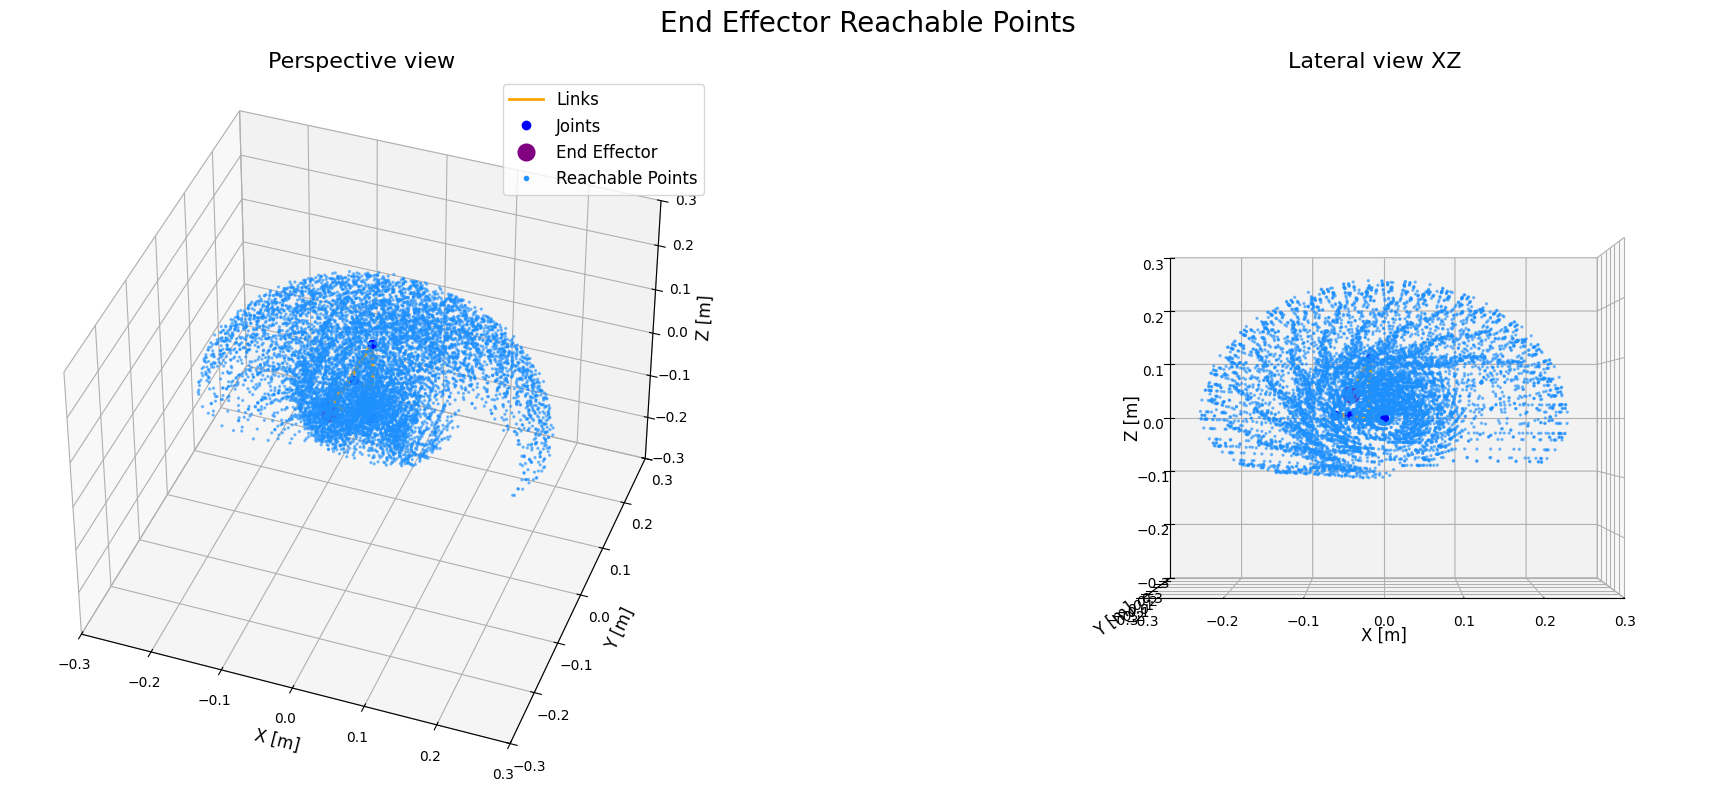

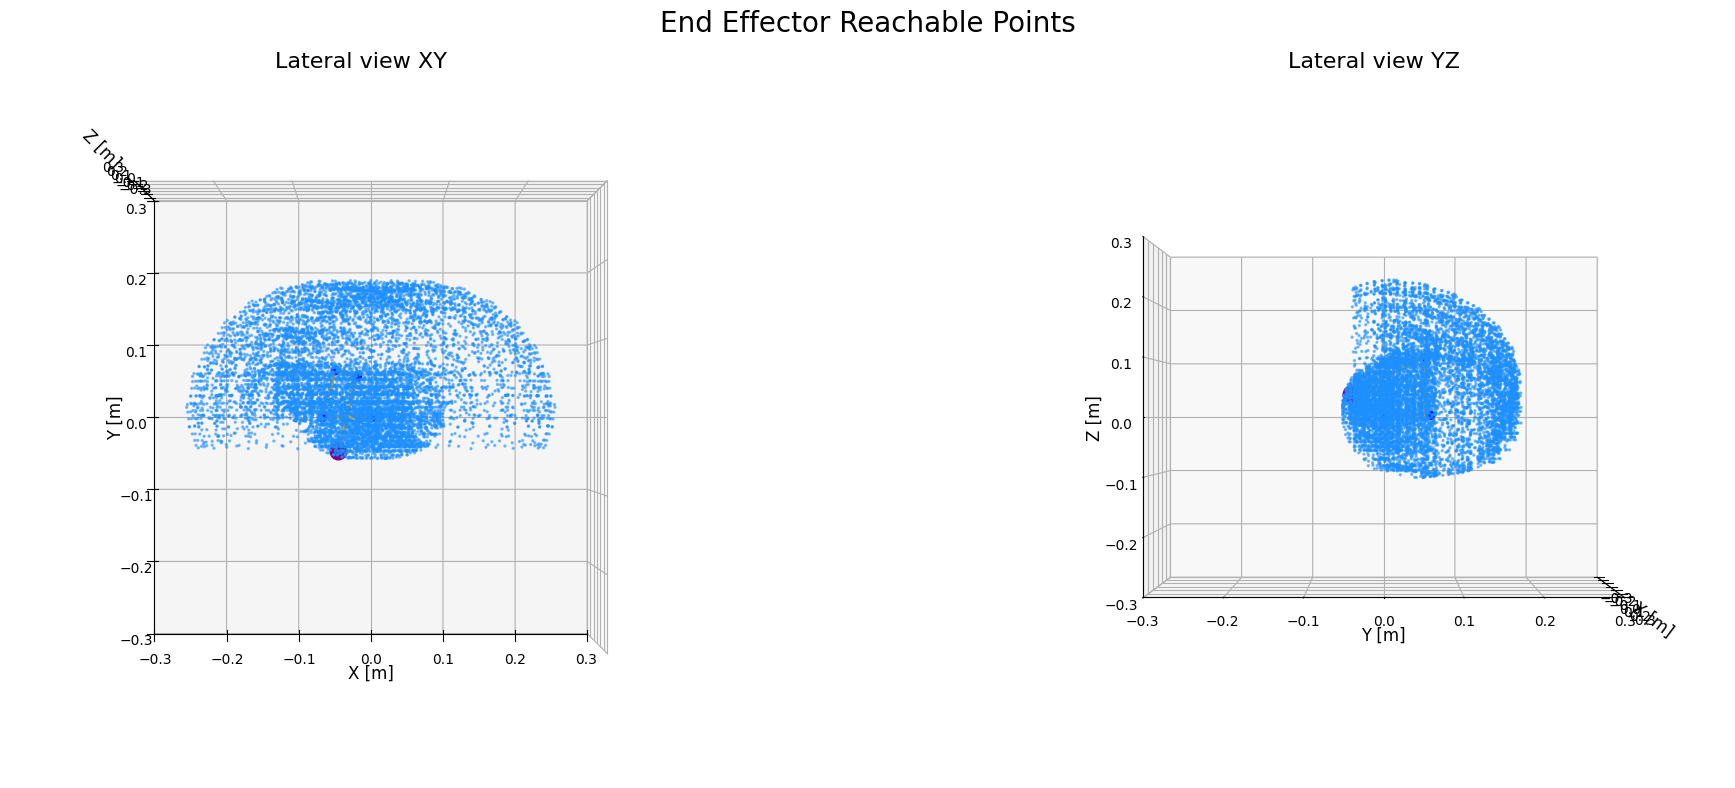

In [7]:
fig = plt.figure(figsize=(22, 8))
ax1 = fig.add_subplot(121, projection='3d')
ax1.set_title('Perspective view', fontsize=16)

# Scatter dei punti raggiungibili
ax1.scatter(reachable_points[:, 0], reachable_points[:, 1], reachable_points[:, 2], s=2, c='dodgerblue', alpha=0.5)

# Link del robot
ax1.plot3D([p0[0], p1[0]], [p0[1], p1[1]], [p0[2], p1[2]], lw=3, color='orange')
ax1.plot3D([p1[0], p2[0]], [p1[1], p2[1]], [p1[2], p2[2]], lw=3, color='orange')
ax1.plot3D([p2[0], p3[0]], [p2[1], p3[1]], [p2[2], p3[2]], lw=3, color='orange')
ax1.plot3D([p3[0], p3[0]], [p3[1], p3[1]], [p3[2], p3[2] + d4], lw=3, color='orange')
ax1.plot3D([p3[0], pee[0]], [p3[1], pee[1]], [p3[2] + d4, pee[2]], lw=3, color='orange')

# Giunti
ax1.plot3D(p0[0], p0[1], p0[2], '.', ms=12, c='blue')
ax1.plot3D(p1[0], p1[1], p1[2], '.', ms=12, c='blue')
ax1.plot3D(p2[0], p2[1], p2[2], '.', ms=12, c='blue')
ax1.plot3D(p3[0], p3[1], p3[2]+d4, '.', ms=12, c='blue')

# End effector
ax1.plot3D(pee[0], pee[1], pee[2], 'o', ms=12, c='purple')

# Legenda
legend_elements = [
    Line2D([0], [0], color='orange', lw=2, label='Links'),
    Line2D([0], [0], marker='.', linestyle='None', color='blue', label='Joints', markersize=12),
    Line2D([0], [0], marker='o', linestyle='None', color='purple', label='End Effector', markersize=12),
    Line2D([0], [0], marker='.', linestyle='None', color='dodgerblue', label='Reachable Points', markersize=6)
]
ax1.legend(handles=legend_elements, loc='best', fontsize=12)

ax1.set_xlim([-0.3, 0.3])
ax1.set_ylim([-0.3, 0.3])
ax1.set_zlim([-0.3, 0.3])
ax1.set_xticks(np.arange(-0.3, 0.4, 0.1))
ax1.set_yticks(np.arange(-0.3, 0.4, 0.1))
ax1.set_zticks(np.arange(-0.3, 0.4, 0.1))
ax1.set_xlabel('X [m]', fontsize=12)
ax1.set_ylabel('Y [m]', fontsize=12)
ax1.set_zlabel('Z [m]', fontsize=12)
ax1.view_init(40, 110)
ax1.invert_xaxis()
ax1.invert_yaxis()

# Vista laterale XZ
ax2 = fig.add_subplot(122, projection='3d')
ax2.set_title('Lateral view XZ', fontsize=16)
ax2.scatter(reachable_points[:, 0], reachable_points[:, 1], reachable_points[:, 2], s=2, c='dodgerblue', alpha=0.5)
ax2.plot3D([p0[0], p1[0]], [p0[1], p1[1]], [p0[2], p1[2]], lw=3, color='orange')
ax2.plot3D([p1[0], p2[0]], [p1[1], p2[1]], [p1[2], p2[2]], lw=3, color='orange')
ax2.plot3D([p2[0], p3[0]], [p2[1], p3[1]], [p2[2], p3[2]], lw=3, color='orange')
ax2.plot3D([p3[0], p3[0]], [p3[1], p3[1]], [p3[2], p3[2] + d4], lw=3, color='orange')
ax2.plot3D([p3[0], pee[0]], [p3[1], pee[1]], [p3[2] + d4, pee[2]], lw=3, color='orange')

# Giunti
ax2.plot3D(p0[0], p0[1], p0[2], '.', ms=12, c='blue')
ax2.plot3D(p1[0], p1[1], p1[2], '.', ms=12, c='blue')
ax2.plot3D(p2[0], p2[1], p2[2], '.', ms=12, c='blue')
ax2.plot3D(p3[0], p3[1], p3[2]+d4, '.', ms=12, c='blue')

# End effector
ax2.plot3D(pee[0], pee[1], pee[2], 'o', ms=12, c='purple')

ax2.set_xlim([-0.3, 0.3])
ax2.set_ylim([-0.3, 0.3])
ax2.set_zlim([-0.3, 0.3])
ax2.set_xlabel('X [m]', fontsize=12)
ax2.set_ylabel('Y [m]', fontsize=12)
ax2.set_zlabel('Z [m]', fontsize=12)
ax2.set_xticks(np.arange(-0.3, 0.4, 0.1))
ax2.set_yticks(np.arange(-0.3, 0.4, 0.1))
ax2.set_zticks(np.arange(-0.3, 0.4, 0.1))
ax2.view_init(0, 90)
ax2.invert_xaxis()
ax2.invert_yaxis()

plt.suptitle('End Effector Reachable Points', fontsize=20)
plt.tight_layout()
plt.show()

# Vista XY e YZ in secondo blocco
fig2 = plt.figure(figsize=(22, 8))

ax3 = fig2.add_subplot(121, projection='3d')
ax3.set_title('Lateral view XY', fontsize=16)
ax3.scatter(reachable_points[:, 0], reachable_points[:, 1], reachable_points[:, 2], s=2, c='dodgerblue', alpha=0.5)
ax3.plot3D([p0[0], p1[0]], [p0[1], p1[1]], [p0[2], p1[2]], lw=3, color='orange')
ax3.plot3D([p1[0], p2[0]], [p1[1], p2[1]], [p1[2], p2[2]], lw=3, color='orange')
ax3.plot3D([p2[0], p3[0]], [p2[1], p3[1]], [p2[2], p3[2]], lw=3, color='orange')
ax3.plot3D([p3[0], p3[0]], [p3[1], p3[1]], [p3[2], p3[2] + d4], lw=3, color='orange')
ax3.plot3D([p3[0], pee[0]], [p3[1], pee[1]], [p3[2] + d4, pee[2]], lw=3, color='orange')

# Giunti
ax3.plot3D(p0[0], p0[1], p0[2], '.', ms=12, c='blue')
ax3.plot3D(p1[0], p1[1], p1[2], '.', ms=12, c='blue')
ax3.plot3D(p2[0], p2[1], p2[2], '.', ms=12, c='blue')
ax3.plot3D(p3[0], p3[1], p3[2]+d4, '.', ms=12, c='blue')

# End effector
ax3.plot3D(pee[0], pee[1], pee[2], 'o', ms=12, c='purple')

ax3.set_xlim([-0.3, 0.3])
ax3.set_ylim([-0.3, 0.3])
ax3.set_zlim([-0.3, 0.3])
ax3.set_xlabel('X [m]', fontsize=12)
ax3.set_ylabel('Y [m]', fontsize=12)
ax3.set_zlabel('Z [m]', fontsize=12)
ax3.set_xticks(np.arange(-0.3, 0.4, 0.1))
ax3.set_yticks(np.arange(-0.3, 0.4, 0.1))
ax3.set_zticks(np.arange(-0.3, 0.4, 0.1))
ax3.view_init(90, 90)
ax3.invert_xaxis()
ax3.invert_yaxis()

ax4 = fig2.add_subplot(122, projection='3d')
ax4.set_title('Lateral view YZ', fontsize=16)
ax4.scatter(reachable_points[:, 0], reachable_points[:, 1], reachable_points[:, 2], s=2, c='dodgerblue', alpha=0.5)
ax4.plot3D([p0[0], p1[0]], [p0[1], p1[1]], [p0[2], p1[2]], lw=3, color='orange')
ax4.plot3D([p1[0], p2[0]], [p1[1], p2[1]], [p1[2], p2[2]], lw=3, color='orange')
ax4.plot3D([p2[0], p3[0]], [p2[1], p3[1]], [p2[2], p3[2]], lw=3, color='orange')
ax4.plot3D([p3[0], p3[0]], [p3[1], p3[1]], [p3[2], p3[2] + d4], lw=3, color='orange')
ax4.plot3D([p3[0], pee[0]], [p3[1], pee[1]], [p3[2] + d4, pee[2]], lw=3, color='orange')

# Giunti
ax4.plot3D(p0[0], p0[1], p0[2], '.', ms=12, c='blue')
ax4.plot3D(p1[0], p1[1], p1[2], '.', ms=12, c='blue')
ax4.plot3D(p2[0], p2[1], p2[2], '.', ms=12, c='blue')
ax4.plot3D(p3[0], p3[1], p3[2]+d4, '.', ms=12, c='blue')

# End effector
ax4.plot3D(pee[0], pee[1], pee[2], 'o', ms=12, c='purple')

ax4.set_xlim([-0.3, 0.3])
ax4.set_ylim([-0.3, 0.3])
ax4.set_zlim([-0.3, 0.3])
ax4.set_xlabel('X [m]', fontsize=12)
ax4.set_ylabel('Y [m]', fontsize=12)
ax4.set_zlabel('Z [m]', fontsize=12)
ax4.set_xticks(np.arange(-0.3, 0.4, 0.1))
ax4.set_yticks(np.arange(-0.3, 0.4, 0.1))
ax4.set_zticks(np.arange(-0.3, 0.4, 0.1))
ax4.view_init(0, 180)
ax4.invert_xaxis()
ax4.invert_yaxis()

plt.suptitle('End Effector Reachable Points', fontsize=20)
plt.tight_layout()
plt.show()
